# Miniproyecto 6 · Un agente de viajes con herramientas MCP

### Cuando recuperar texto no alcanza

**Maestría en Inteligencia Artificial y Ciencia de Datos · Universidad Icesi · NLP**

Juan José Aguado · Juan David Cruz · Juan Diego Ramírez

## 0. El problema y lo que encontramos

El Miniproyecto 5 montó un RAG sobre reseñas turísticas y fichas de Wikipedia, y dejó a la vista
un límite que no se arregla con mejores *embeddings*: **hay preguntas que no se responden
recuperando documentos.** Si alguien pregunta *«¿cuántas reseñas de 1 estrella tiene Tulum?»*, un
RAG recupera cinco reseñas y el modelo **estima** la cifra a partir de esa muestra, que es una
forma educada de inventarla. Una agregación no se recupera: **se calcula.**

**MCP** (*Model Context Protocol*) es el protocolo estándar para exponer herramientas a un modelo,
con servidor, transporte y cliente separados. Le damos al agente cuatro herramientas sobre el mismo
corpus de las entregas anteriores, dos que **calculan** y dos que **recuperan**, y con las dos vías
disponibles para la misma pregunta lo que importa ya no es si la herramienta funciona:

> **¿Cuándo conviene una herramienta y cuándo basta con recuperar texto, y sabe el agente elegir?**

| Servidor MCP | Herramienta | Qué hace | Naturaleza |
|---|---|---|---|
| `corpus_mcp_server` (puerto 9090) | `estadisticas_destino` | conteos, media de estrellas, reparto por tipo | **calcula** |
| | `comparar_destinos` | ranking de destinos por valoración media | **calcula** |
| `busqueda_mcp_server` (puerto 9091) | `buscar_resenas` | búsqueda semántica con filtros de metadatos | **recupera** |
| | `ficha_destino` | la ficha de Wikipedia del destino | **recupera** |

**Hipótesis.** **H1**: en preguntas de agregación el agente con herramientas da la cifra exacta y
el modelo solo o el RAG fallan. **H2**: el cuello de botella no es la herramienta, que acierta por
construcción, sino la **elección** (no llamarla, llamar otra o pasar mal los argumentos). **H3**:
con más herramientas y descripciones parecidas, la elección empeora.

### Lo que encontramos (corrida de referencia, 26 preguntas, CPU)

| Camino | Agregación (cifra exacta) | Experiencia (evidencia pertinente) | Hecho (estado correcto) |
|---|---:|---:|---:|
| Modelo solo, sin herramientas | 1 de 12 | sin evidencia | 4 de 6 |
| RAG puro, como en MP5 | 1 de 12 | 0,70 | 6 de 6 |
| **Agente con 4 herramientas MCP** | **11 de 12** | **0,88** | **6 de 6** |

- **H1 confirmada.** Solo el agente da cifras exactas. El modelo solo inventa números «de TripAdvisor» y el RAG, que ve cinco reseñas, llega a afirmar que Tulum no tiene reseñas de 1 estrella (tiene 798).
- **H2 parcial.** Con buenas descripciones la elección fue perfecta (26 de 26): los tres errores observados fueron un argumento inventado, una cifra mal leída de la salida de la herramienta y un esquema que rechazaba `null` (D-610). La elección solo se vuelve el cuello de botella cuando las descripciones son pobres.
- **H3 refutada tal como la planteamos.** Pasar de 2 a 4 herramientas **no** empeoró la elección (94 % frente a 100 %). Lo que la hunde es la calidad de la descripción: con docstrings de una línea la selección cae al 47 % y la cifra exacta al 0 %, porque el agente manda todo a `buscar_resenas`.

El detalle está en §7 a §9 y las conclusiones en §11.

---

## 1. Entorno y reproducibilidad

Tres decisiones sostienen la reproducibilidad. El modelo se fija **por nombre y etiqueta**
(`llama3.2:3b`), porque «el último» cambia sin avisar. La **temperatura es 0** y la semilla 42,
porque un agente con temperatura alta elige herramientas distintas en cada corrida y las métricas
de §7 y §8 dejarían de reproducirse. Y todo **degrada en vez de fallar**: sin GPU los *embeddings*
corren en CPU, y sin Ollama las secciones de agente avisan y se saltan. La variable de entorno
`MP6_SOLO_CPU=1` obliga a Ollama a no usar la GPU; la corrida de referencia se hizo así.

In [1]:
import asyncio, json, os, random, re, signal, socket, subprocess, sys, time, unicodedata, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
import torch

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="IProgress not found")   # barra de progreso de tqdm
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# Rutas relativas a la raíz del repositorio, se ejecute desde notebooks/ o desde la raíz.
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATOS, FIGURAS, METRICAS = RAIZ / "data", RAIZ / "results" / "figures", RAIZ / "results" / "metrics"
for carpeta in (DATOS, FIGURAS, METRICAS):
    carpeta.mkdir(parents=True, exist_ok=True)

MODELO_LLM = "llama3.2:3b"            # fijado por etiqueta, nunca "latest"
TEMPERATURA = 0.0                     # elección de herramienta determinista
MODELO_EMB = "intfloat/multilingual-e5-small"   # el codificador del Miniproyecto 5
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
OPCIONES_OLLAMA = {"num_gpu": 0} if os.environ.get("MP6_SOLO_CPU") == "1" else {}
OLLAMA_URL = os.environ.get("OLLAMA_HOST", "http://localhost:11434")
OLLAMA_URL = OLLAMA_URL if OLLAMA_URL.startswith("http") else f"http://{OLLAMA_URL}"


def ollama_listo():
    try:
        modelos = [m["name"] for m in requests.get(f"{OLLAMA_URL}/api/tags", timeout=5).json()["models"]]
    except requests.RequestException:
        return False, f"Ollama no responde en {OLLAMA_URL}"
    if MODELO_LLM not in modelos:
        return False, f"falta el modelo, ejecutar: ollama pull {MODELO_LLM}"
    return True, "listo"


OLLAMA_OK, estado_ollama = ollama_listo()
sns.set_theme(style="whitegrid", context="notebook")
print(f"Python {sys.version.split()[0]} | torch {torch.__version__} | embeddings en {DEVICE}")
print(f"Ollama: {estado_ollama} | {MODELO_LLM} | temperatura {TEMPERATURA} | semilla {SEED} | "
      f"{'solo CPU' if OPCIONES_OLLAMA else 'GPU si hay'}")
if not OLLAMA_OK:
    print("AVISO: sin Ollama las secciones 5 a 10 se saltan con un mensaje; el resto corre igual.")
T_INICIO = time.perf_counter()

Python 3.12.14 | torch 2.14.1+cpu | embeddings en cpu
Ollama: listo | llama3.2:3b | temperatura 0.0 | semilla 42 | solo CPU


---

## 2. El corpus que ven las herramientas

Reutilizamos los **datos** de las entregas anteriores, no sus celdas (D-602): las reseñas de
**Rest-Mex 2025** (`vg055/Rest-Mex2025` en HuggingFace) y las 40 fichas de Wikipedia que construyó
el Miniproyecto 5 (`data/fichas_destino.json`, CC BY-SA 4.0). El corpus se guarda en
`data/restmex.parquet` porque **los servidores MCP lo leen al arrancar**: así se descarga una sola
vez y el notebook y los servidores ven exactamente los mismos datos.

In [2]:
from datasets import load_dataset

RUTA_CORPUS = DATOS / "restmex.parquet"
if not RUTA_CORPUS.exists():
    crudo = load_dataset("vg055/Rest-Mex2025", split="train").to_pandas()
    crudo["Title"] = crudo["Title"].fillna("")          # 2 reseñas sin título
    crudo.to_parquet(RUTA_CORPUS, index=False)
corpus = pd.read_parquet(RUTA_CORPUS)
fichas = json.loads((DATOS / "fichas_destino.json").read_text("utf-8"))["fichas"]

pd.Series({
    "Reseñas": len(corpus),
    "Destinos": corpus["Town"].nunique(),
    "Estados": corpus["Region"].nunique(),
    "Tipos de lugar": corpus["Type"].nunique(),
    "Fichas de Wikipedia": len(fichas),
    "Palabras en las fichas": sum(int(f["palabras"]) for f in fichas),
}).to_frame("valor")

,valor
Reseñas,208051
Destinos,40
Estados,19
Tipos de lugar,3
Fichas de Wikipedia,40
Palabras en las fichas,131920


### 2.1 EDA: lo que las herramientas tienen que saber contar

El EDA se limita a lo que condiciona el diseño de las herramientas (aquí no se clasifica nada):
cuántas reseñas tiene cada destino, cómo se reparten las estrellas y qué tan confiable es una
media según cuántas reseñas la sostienen.

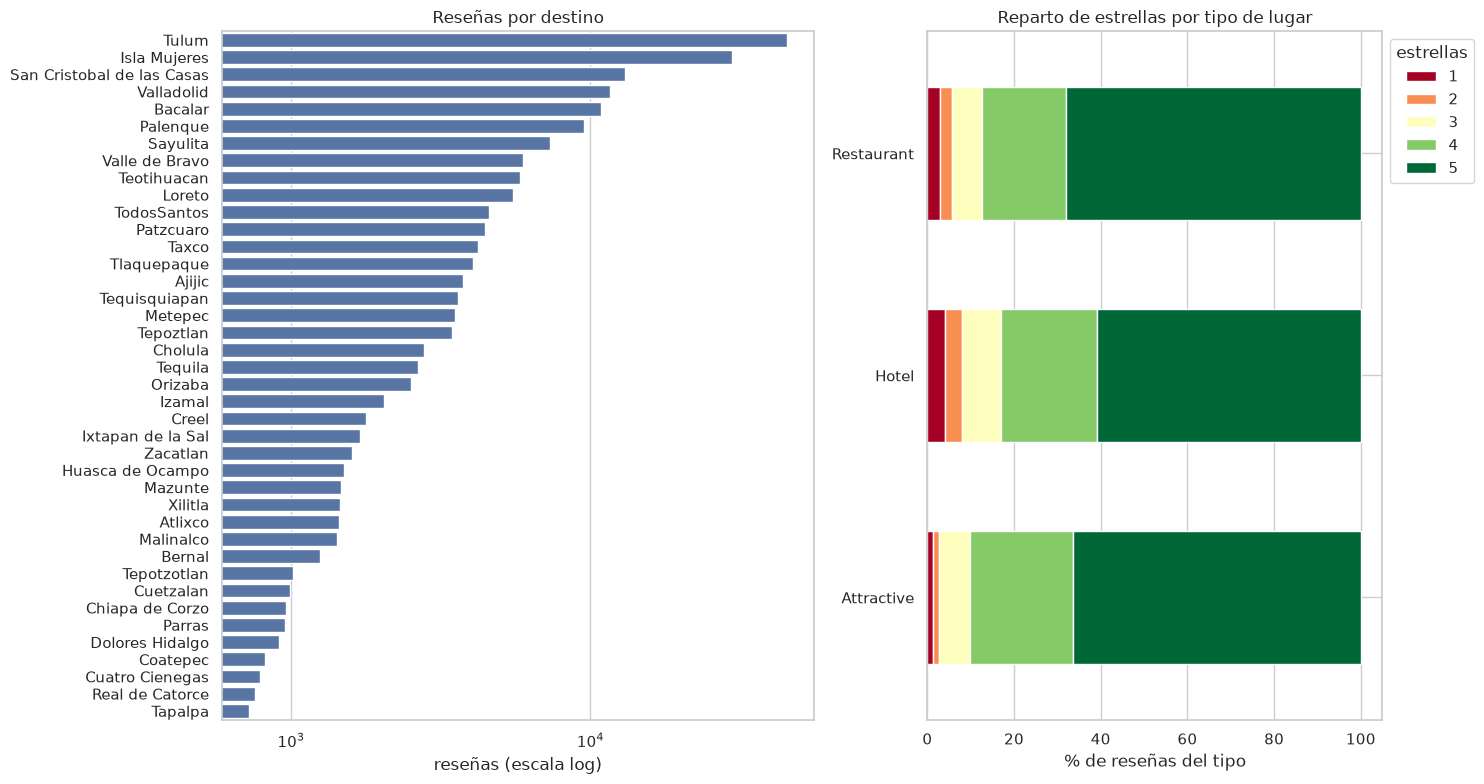

Tulum concentra el 21.8% del corpus; el destino más pequeño (Tapalpa) tiene 725 reseñas.
Reseñas de 5 estrellas: 65.6%; de 1 y 2 estrellas: 5.3%.


In [3]:
por_destino = corpus["Town"].value_counts()
fig, ejes = plt.subplots(1, 2, figsize=(15, 8), gridspec_kw={"width_ratios": [1.3, 1]})
sns.barplot(x=por_destino.values, y=por_destino.index.str.replace("_", " "), ax=ejes[0], color="#4C72B0")
ejes[0].set(xscale="log", xlabel="reseñas (escala log)", ylabel="", title="Reseñas por destino")

estrellas = pd.crosstab(corpus["Type"], corpus["Polarity"].astype(int), normalize="index") * 100
estrellas.plot(kind="barh", stacked=True, ax=ejes[1], colormap="RdYlGn", width=0.6)
ejes[1].set(xlabel="% de reseñas del tipo", ylabel="", title="Reparto de estrellas por tipo de lugar")
ejes[1].legend(title="estrellas", bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.savefig(FIGURAS / "01_eda_corpus.png", dpi=110); plt.show()

print(f"Tulum concentra el {por_destino.iloc[0] / len(corpus):.1%} del corpus; "
      f"el destino más pequeño ({por_destino.index[-1]}) tiene {por_destino.iloc[-1]} reseñas.")
print(f"Reseñas de 5 estrellas: {(corpus['Polarity'] == 5).mean():.1%}; de 1 y 2 estrellas: "
      f"{(corpus['Polarity'] <= 2).mean():.1%}.")

**Lectura.** El corpus está muy desbalanceado en las dos dimensiones que importan. Por volumen, Tulum tiene 45.345 reseñas (el 21,8 % del corpus) y Tapalpa solo 725: una diferencia de más de 60 veces, que hace inútil cualquier estimación «a ojo» a partir de una muestra. Por polaridad, el 65,6 % de las reseñas son de 5 estrellas y solo el 5,3 % de 1 o 2, con la media global en 4,45. Los hoteles son el tipo más crítico (media 4,32 y 8,1 % de reseñas negativas, frente al 2,8 % de las atracciones). Dos consecuencias de diseño: las quejas son escasas, así que `buscar_resenas` necesita el filtro `estrellas_max` para encontrarlas (los *embeddings* recuperan por tema, no por polaridad, como mostró MP5); y como la media global es tan alta, las diferencias entre destinos son de décimas, lo que exige cifras exactas y no aproximaciones.

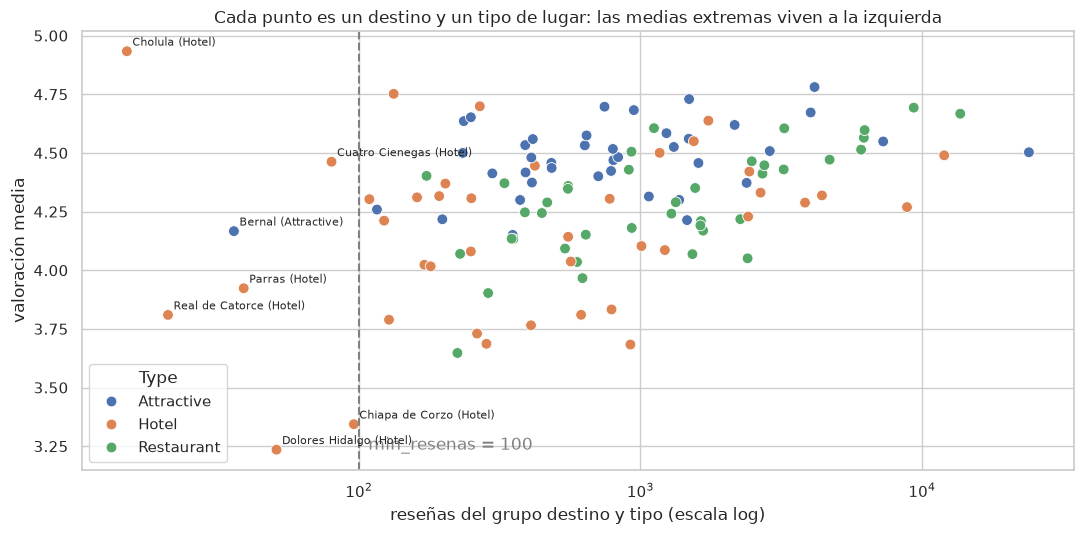

,Town,Type,media,resenas
16,Cholula,Hotel,4.933333,15
70,Real_de_Catorce,Hotel,3.809524,21
9,Bernal,Attractive,4.166667,36
64,Parras,Hotel,3.923077,39
31,Dolores_Hidalgo,Hotel,3.235294,51
25,Cuatro_Cienegas,Hotel,4.462500,80


In [4]:
grupos = corpus.groupby(["Town", "Type"])["Polarity"].agg(media="mean", resenas="size").reset_index()
fig, eje = plt.subplots(figsize=(11, 5.5))
sns.scatterplot(data=grupos, x="resenas", y="media", hue="Type", s=60, ax=eje)
eje.axvline(100, color="gray", ls="--")
eje.text(108, grupos["media"].min(), "min_resenas = 100", color="gray")
for _, g in grupos[grupos["resenas"] < 100].iterrows():
    eje.annotate(f"{g['Town'].replace('_', ' ')} ({g['Type']})", (g["resenas"], g["media"]), fontsize=8,
                 xytext=(4, 4), textcoords="offset points")
eje.set(xscale="log", xlabel="reseñas del grupo destino y tipo (escala log)", ylabel="valoración media",
        title="Cada punto es un destino y un tipo de lugar: las medias extremas viven a la izquierda")
plt.tight_layout(); plt.savefig(FIGURAS / "02_eda_media_vs_volumen.png", dpi=110); plt.show()
grupos.sort_values("resenas").head(6)

**Lectura.** Las 120 combinaciones de destino y tipo tienen medias entre 3,24 y 4,93, y **las dos puntas son grupos de menos de 100 reseñas**: los hoteles de Dolores Hidalgo (3,24 con 51 reseñas) y los de Cholula (4,93 con solo 15). Con muchas reseñas las medias se concentran entre 4,1 y 4,6. Es el clásico efecto de muestra pequeña, y es la razón del parámetro `min_resenas = 100` de `comparar_destinos`: sin él, la pregunta «¿qué destino tiene los mejores hoteles?» la ganaría Cholula con 15 opiniones. Siete grupos quedan por debajo del umbral, todos de hoteles salvo las atracciones de Bernal.

### 2.2 El índice de búsqueda para `buscar_resenas`

La herramienta de recuperación necesita *embeddings*. Codificar las 208.051 reseñas en CPU toma
cerca de media hora, así que el índice usa una **muestra estratificada de hasta 250 reseñas por
destino y tipo**: conserva los 120 grupos (incluidos los pequeños, que se toman completos) y cabe
en pocos minutos. Esta decisión tiene una consecuencia que se mide en §9: el índice ve una
fracción del corpus, y **por eso no puede contar**. Las herramientas de cálculo, en cambio, leen
el corpus completo.

Se usa el codificador de MP5 con sus **prefijos asimétricos** de E5: `passage: ` para los
documentos y `query: ` para la consulta. Omitirlos no da error, solo degrada la recuperación.

In [5]:
from sentence_transformers import SentenceTransformer

MAX_POR_GRUPO = 250
RUTA_INDICE, RUTA_VECTORES = DATOS / "restmex_indice.parquet", DATOS / "vectorstore_e5.npy"
indice = (corpus.sample(frac=1, random_state=SEED).groupby(["Town", "Type"]).head(MAX_POR_GRUPO)
          .sort_index().reset_index(drop=True))

codificador = SentenceTransformer(MODELO_EMB, device=DEVICE)
codificador.max_seq_length = 256      # cubre el 98 % de las reseñas completas
if RUTA_VECTORES.exists() and RUTA_INDICE.exists() and pd.read_parquet(RUTA_INDICE).equals(indice):
    vectores, origen = np.load(RUTA_VECTORES), "caché"
else:
    t0 = time.perf_counter()
    textos = ("passage: " + indice["Title"] + ". " + indice["Review"]).tolist()
    vectores = codificador.encode(textos, batch_size=64, normalize_embeddings=True).astype(np.float32)
    indice.to_parquet(RUTA_INDICE, index=False)
    np.save(RUTA_VECTORES, vectores)
    origen = f"calculado en {time.perf_counter() - t0:.0f} s"
print(f"Índice: {len(indice):,} reseñas ({len(indice) / len(corpus):.1%} del corpus), "
      f"vectores {vectores.shape}, {origen}.")

Índice: 27,400 reseñas (13.2% del corpus), vectores (27400, 384), calculado en 524 s.


---

## 3. Qué es MCP y por qué no es «una función más»

Darle una función de Python a un agente funciona, pero ata la herramienta al programa que la usa.
MCP separa las piezas para que **cualquier cliente compatible** (este notebook, Claude Desktop, un
IDE) use el mismo servidor sin saber nada de su código:

| Pieza | En este proyecto | Qué hace |
|---|---|---|
| **Servidor** | `mcp_servers/corpus_mcp_server.py` y `busqueda_mcp_server.py` (`FastMCP`) | publica herramientas con nombre, descripción y esquema de argumentos |
| **Transporte** | `streamable-http` en `localhost:9090/mcp` y `localhost:9091/mcp` | lleva los mensajes JSON-RPC entre procesos |
| **Cliente** | `ClientSession` de `mcp` (§4) y `MultiServerMCPClient` de `langchain-mcp-adapters` (§6) | descubre las herramientas (`list_tools`) y las invoca (`call_tool`) |
| **Invocación** | el modelo decide la herramienta y sus argumentos; el agente hace la llamada | el resultado vuelve como texto al contexto del modelo |

```
  pregunta ──► agente (llama3.2:3b) ──tool_call──► cliente MCP ──HTTP/JSON-RPC──► servidor MCP ──► pandas / E5
                     ▲                                                               │
                     └──────────────────────── resultado (texto) ◄───────────────────┘
```

**Por qué HTTP y no `stdio`** (D-603): `stdio` obliga a que el cliente lance el servidor como
subproceso propio y da problemas en Colab; con HTTP los servidores son procesos independientes que
varios clientes comparten. El precio es que hay procesos que **arrancar y apagar**, y un servidor
olvidado deja el puerto ocupado para la siguiente ejecución. Por eso §4 los arranca y la última
celda los apaga, y ese apagado se puede repetir sin error.

Un detalle que convierte las descripciones en parte del experimento: **el agente elige la
herramienta leyendo su nombre y su docstring**, que el servidor publica por el protocolo. No son
documentación para humanos, son la entrada del clasificador que decide. Cada docstring dice
cuándo usar la herramienta y **cuándo no**.

---

## 4. Los servidores y sus herramientas

Los servidores se lanzan como procesos independientes y sus PID se guardan en `mcp_servers/.pids`.
Antes de arrancar se apaga cualquier servidor que haya dejado una ejecución anterior interrumpida,
de modo que «Restart & Run All» funciona aunque la corrida previa se haya cortado a la mitad.

In [6]:
SERVIDORES = {"corpus": ("corpus_mcp_server.py", 9090), "busqueda": ("busqueda_mcp_server.py", 9091)}
CARPETA_MCP = RAIZ / "mcp_servers"
ARCHIVO_PIDS = CARPETA_MCP / ".pids"


def puerto_abierto(puerto):
    with socket.socket() as s:
        return s.connect_ex(("localhost", puerto)) == 0


def apagar_servidores():
    """Idempotente: si no hay nada corriendo, no hace nada y no falla."""
    pids = [int(p) for p in ARCHIVO_PIDS.read_text().split()] if ARCHIVO_PIDS.exists() else []
    for pid in pids:
        try:
            os.kill(pid, signal.SIGTERM)
        except (ProcessLookupError, PermissionError, OSError):
            pass
    for _ in range(50):
        if not any(puerto_abierto(p) for _, p in SERVIDORES.values()):
            break
        time.sleep(0.2)
    ARCHIVO_PIDS.unlink(missing_ok=True)
    return {nombre: "libre" if not puerto_abierto(p) else "OCUPADO" for nombre, (_, p) in SERVIDORES.items()}


def arrancar_servidores(espera_max=240):
    apagar_servidores()
    ocupados = [p for _, p in SERVIDORES.values() if puerto_abierto(p)]
    if ocupados:
        raise RuntimeError(f"Puertos {ocupados} ocupados por otro programa: ciérralo y vuelve a ejecutar.")
    entorno = {**os.environ, "MP6_DEVICE": DEVICE, "PYTHONUNBUFFERED": "1"}
    procesos = {}
    for nombre, (script, _) in SERVIDORES.items():
        log = open(CARPETA_MCP / f"{nombre}.log", "w")
        procesos[nombre] = subprocess.Popen([sys.executable, script], cwd=CARPETA_MCP, env=entorno,
                                            stdout=log, stderr=subprocess.STDOUT)
    ARCHIVO_PIDS.write_text(" ".join(str(p.pid) for p in procesos.values()))
    t0 = time.perf_counter()
    while not all(puerto_abierto(p) for _, p in SERVIDORES.values()):
        caidos = [n for n, p in procesos.items() if p.poll() is not None]
        if caidos or time.perf_counter() - t0 > espera_max:
            apagar_servidores()
            raise RuntimeError(f"Fallo al arrancar {caidos or 'por tiempo'}: ver mcp_servers/*.log")
        time.sleep(0.5)
    return procesos, time.perf_counter() - t0


procesos_mcp, t_arranque = arrancar_servidores()
print(f"Servidores arriba en {t_arranque:.1f} s: " +
      ", ".join(f"{n} (PID {p.pid}, puerto {SERVIDORES[n][1]})" for n, p in procesos_mcp.items()))

Servidores arriba en 10.0 s: corpus (PID 170874, puerto 9090), busqueda (PID 170875, puerto 9091)


### 4.1 Un cliente MCP desnudo

Antes de dárselas al agente, las herramientas se descubren y se prueban con el **cliente de bajo
nivel** del paquete `mcp`: se abre el transporte HTTP, se inicia la sesión con el saludo del
protocolo, se pide la lista de herramientas y se invoca cada una. Nada de esto importa código de
los servidores: todo lo que el cliente sabe de ellas llega por el protocolo.

In [7]:
from mcp import ClientSession
from mcp.client.streamable_http import streamable_http_client


async def sesion_mcp(puerto, herramienta=None, argumentos=None):
    """Abre transporte y sesión; lista las herramientas o invoca una."""
    async with streamable_http_client(f"http://localhost:{puerto}/mcp") as (lectura, escritura, _):
        async with ClientSession(lectura, escritura) as sesion:
            await sesion.initialize()
            if herramienta is None:
                return (await sesion.list_tools()).tools
            resultado = await sesion.call_tool(herramienta, argumentos or {})
            return resultado.content[0].text


catalogo = []
for servidor, (_, puerto) in SERVIDORES.items():
    for h in await sesion_mcp(puerto):
        catalogo.append({"servidor": servidor, "herramienta": h.name,
                         "argumentos": ", ".join(h.inputSchema["properties"]),
                         "descripción (primera línea)": h.description.split("\n")[0][:90]})
pd.DataFrame(catalogo)

,servidor,herramienta,argumentos,descripción (primera línea)
0,corpus,estadisticas_destino,destino,Calcula cifras EXACTAS de un destino turístico...
1,corpus,comparar_destinos,"n, tipo, min_resenas, peores",Ordena TODOS los destinos del corpus por valor...
2,busqueda,buscar_resenas,"consulta, destino, tipo, estrellas_max, k",Busca reseñas REALES de turistas por similitud...
3,busqueda,ficha_destino,destino,Devuelve la ficha enciclopédica de Wikipedia d...


Ahora cada herramienta con una entrada de prueba, midiendo la ida y vuelta completa por el
protocolo. Las entradas están escritas **como las escribiría el agente** (con espacios y tildes)
y no como las guarda el corpus (`San_Cristobal_de_las_Casas`), porque esa traducción es
responsabilidad del servidor.

In [8]:
PRUEBAS = [
    (9090, "estadisticas_destino", {"destino": "San Cristóbal de las Casas"}),
    (9090, "comparar_destinos", {"n": 3, "tipo": "Restaurant"}),
    (9091, "buscar_resenas", {"consulta": "quejas sobre la limpieza", "destino": "Tulum",
                              "tipo": "Hotel", "estrellas_max": 2, "k": 3}),
    (9091, "ficha_destino", {"destino": "Real de Catorce"}),
]
latencias = []
for puerto, herramienta, args in PRUEBAS:
    t0 = time.perf_counter()
    salida = await sesion_mcp(puerto, herramienta, args)
    latencias.append({"herramienta": herramienta, "ms": round((time.perf_counter() - t0) * 1000)})
    print(f"▶ {herramienta}({args})\n{salida[:700]}\n")
inexistente = await sesion_mcp(9090, "estadisticas_destino", {"destino": "Cancun"})
print(f"Destino inexistente: {inexistente[:160]}...")
pd.DataFrame(latencias)

▶ estadisticas_destino({'destino': 'San Cristóbal de las Casas'})
Destino: San Cristobal de las Casas (Chiapas)
Total de reseñas: 13060
Valoración media: 4.46 de 5 estrellas
Reseñas por estrellas: 1 estrella: 283 | 2 estrellas: 320 | 3 estrellas: 1043 | 4 estrellas: 2847 | 5 estrellas: 8567
Reseñas por tipo: restaurantes: 6260 (media 4.60) | hoteles: 4415 (media 4.32) | atracciones: 2385 (media 4.37)
Fuente: corpus Rest-Mex 2025 completo, cálculo exacto con pandas.

▶ comparar_destinos({'n': 3, 'tipo': 'Restaurant'})
Ranking de destinos mejor valorados (restaurantes, mínimo 100 reseñas):
1. Tulum: media 4.69 (9353 reseñas)
2. Isla Mujeres: media 4.67 (13687 reseñas)
3. Atlixco: media 4.61 (1118 reseñas)
Destinos que cumplen el mínimo: 40. Fuente: corpus Rest-Mex 2025, cálculo exacto.

▶ buscar_resenas({'consulta': 'quejas sobre la limpieza', 'destino': 'Tulum', 'tipo': 'Hotel', 'estrellas_max': 2, 'k': 3})
3 reseñas más parecidas a 'quejas sobre la limpieza' con filtros destino=Tulum, 

,herramienta,ms
0,estadisticas_destino,55
1,comparar_destinos,45
2,buscar_resenas,41
3,ficha_destino,21


**Lectura.** Las cuatro herramientas responden por el protocolo en **entre 20 y 60 ms**, un costo despreciable frente a los varios segundos que tarda el modelo en decidir y redactar (§7). Tres detalles del diseño quedan a la vista: el servidor traduce «San Cristóbal de las Casas» al nombre del corpus, el ranking respeta el mínimo de reseñas, y la búsqueda devuelve **cada reseña con su destino, tipo y estrellas**, que es lo que después permite citar. Un destino inexistente («Cancun») no lanza una excepción: devuelve la lista de destinos válidos, que el agente puede usar para corregirse.

---

## 5. El banco de preguntas y el modelo solo

### 5.1 Un banco con la respuesta correcta calculada

Para medir sin juzgar a ojo (D-604), cada pregunta declara **qué herramienta debería llamarse,
con qué argumentos y cuál es la respuesta correcta**. Hay tres tipos, porque la tesis es que cada
uno pide un camino distinto:

- **Agregación** (12): conteos, medias y rankings. La cifra correcta se calcula aquí con pandas,
  por un camino independiente del servidor, y nunca se escribe a mano.
- **Experiencia** (8): opiniones y quejas. No tienen cifra; se evalúa si la **evidencia**
  recuperada es del destino, tipo y polaridad que pide la pregunta.
- **Hecho** (6): en qué estado está un destino. La respuesta correcta sale de la columna `Region`
  del corpus.

Los argumentos esperados son solo los que la pregunta **pide explícitamente**: si la pregunta dice
«hoteles de Tulum», se exige `destino` y `tipo`; si solo dice «Bacalar», solo `destino`.

In [9]:
def leg(destino):
    return destino.replace("_", " ")


def norm(texto):
    sin_tildes = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9]", "", sin_tildes.lower())


ESTADO = {"QuintanaRoo": "Quintana Roo", "Baja_CaliforniaSur": "Baja California Sur"}


def estado(destino):
    region = corpus.loc[corpus["Town"] == destino, "Region"].iloc[0]
    return ESTADO.get(region, leg(region))


def n_resenas(destino, tipo=None, estrellas=None):
    sub = corpus[corpus["Town"] == destino]
    sub = sub if tipo is None else sub[sub["Type"] == tipo]
    return int(len(sub if estrellas is None else sub[sub["Polarity"] == estrellas]))


def media(destino, tipo=None):
    sub = corpus[corpus["Town"] == destino]
    return float((sub if tipo is None else sub[sub["Type"] == tipo])["Polarity"].mean())


def mejor(tipo=None, peores=False, min_resenas=100):
    sub = corpus if tipo is None else corpus[corpus["Type"] == tipo]
    t = sub.groupby("Town")["Polarity"].agg(["mean", "size"])
    return leg(t[t["size"] >= min_resenas]["mean"].sort_values(ascending=peores).index[0])


A, E, H = "agregacion", "experiencia", "hecho"
filas = [
    ("A01", A, "¿Cuántas reseñas tiene Bacalar en total?", "estadisticas_destino", {"destino": "Bacalar"}, n_resenas("Bacalar"), "conteo"),
    ("A02", A, "¿Cuál es la valoración media de Palenque?", "estadisticas_destino", {"destino": "Palenque"}, media("Palenque"), "media"),
    ("A03", A, "¿Cuántas reseñas de 1 estrella tiene Tulum?", "estadisticas_destino", {"destino": "Tulum"}, n_resenas("Tulum", estrellas=1), "conteo"),
    ("A04", A, "¿Cuántas reseñas de hoteles hay de Valladolid?", "estadisticas_destino", {"destino": "Valladolid"}, n_resenas("Valladolid", "Hotel"), "conteo"),
    ("A05", A, "¿Qué calificación promedio le dan los turistas a Isla Mujeres?", "estadisticas_destino", {"destino": "Isla_Mujeres"}, media("Isla_Mujeres"), "media"),
    ("A06", A, "¿Cuántas opiniones de restaurantes tiene San Cristóbal de las Casas?", "estadisticas_destino", {"destino": "San_Cristobal_de_las_Casas"}, n_resenas("San_Cristobal_de_las_Casas", "Restaurant"), "conteo"),
    ("A07", A, "¿Cuántas reseñas de 5 estrellas tiene Real de Catorce?", "estadisticas_destino", {"destino": "Real_de_Catorce"}, n_resenas("Real_de_Catorce", estrellas=5), "conteo"),
    ("A08", A, "¿Cuál es la valoración media de las atracciones de Taxco?", "estadisticas_destino", {"destino": "Taxco"}, media("Taxco", "Attractive"), "media"),
    ("A09", A, "¿Cuántas reseñas tiene Teotihuacan?", "estadisticas_destino", {"destino": "Teotihuacan"}, n_resenas("Teotihuacan"), "conteo"),
    ("A10", A, "¿Qué destino de México tiene la mejor valoración media?", "comparar_destinos", {}, mejor(), "nombre"),
    ("A11", A, "¿Qué destino tiene los restaurantes mejor valorados?", "comparar_destinos", {"tipo": "Restaurant"}, mejor("Restaurant"), "nombre"),
    ("A12", A, "¿Cuál es el destino con los hoteles peor valorados?", "comparar_destinos", {"tipo": "Hotel", "peores": True}, mejor("Hotel", peores=True), "nombre"),
    ("E01", E, "¿De qué se quejan los turistas en los hoteles de Tulum?", "buscar_resenas", {"destino": "Tulum", "tipo": "Hotel", "estrellas_max": 2}, None, "evidencia"),
    ("E02", E, "¿Qué platillos recomiendan los visitantes en los restaurantes de Valladolid?", "buscar_resenas", {"destino": "Valladolid", "tipo": "Restaurant"}, None, "evidencia"),
    ("E03", E, "¿Qué opinan los turistas de las pirámides de Teotihuacan?", "buscar_resenas", {"destino": "Teotihuacan"}, None, "evidencia"),
    ("E04", E, "¿Qué dicen las reseñas sobre la laguna de Bacalar?", "buscar_resenas", {"destino": "Bacalar"}, None, "evidencia"),
    ("E05", E, "¿Cómo describen los visitantes el ambiente de San Cristóbal de las Casas?", "buscar_resenas", {"destino": "San_Cristobal_de_las_Casas"}, None, "evidencia"),
    ("E06", E, "¿Qué problemas mencionan las reseñas negativas de restaurantes en Isla Mujeres?", "buscar_resenas", {"destino": "Isla_Mujeres", "tipo": "Restaurant", "estrellas_max": 2}, None, "evidencia"),
    ("E07", E, "¿Qué cuentan los turistas sobre las Barrancas del Cobre en Creel?", "buscar_resenas", {"destino": "Creel"}, None, "evidencia"),
    ("E08", E, "¿Qué opinan los huéspedes de los hoteles de Sayulita?", "buscar_resenas", {"destino": "Sayulita", "tipo": "Hotel"}, None, "evidencia"),
    ("H01", H, "¿En qué estado de México está Real de Catorce?", "ficha_destino", {"destino": "Real_de_Catorce"}, estado("Real_de_Catorce"), "texto"),
    ("H02", H, "¿En qué estado se encuentra Creel?", "ficha_destino", {"destino": "Creel"}, estado("Creel"), "texto"),
    ("H03", H, "¿A qué estado pertenece Mazunte?", "ficha_destino", {"destino": "Mazunte"}, estado("Mazunte"), "texto"),
    ("H04", H, "¿En qué estado está Cuatro Ciénegas?", "ficha_destino", {"destino": "Cuatro_Cienegas"}, estado("Cuatro_Cienegas"), "texto"),
    ("H05", H, "¿En qué estado queda Bernal?", "ficha_destino", {"destino": "Bernal"}, estado("Bernal"), "texto"),
    ("H06", H, "¿En qué estado de México está Huasca de Ocampo?", "ficha_destino", {"destino": "Huasca_de_Ocampo"}, estado("Huasca_de_Ocampo"), "texto"),
]
BANCO = pd.DataFrame(filas, columns=["id", "categoria", "pregunta", "herramienta", "args", "valor", "clase"])
BANCO.assign(valor=BANCO["valor"].map(lambda v: round(v, 2) if isinstance(v, float) else v))[
    ["id", "categoria", "pregunta", "herramienta", "valor"]]

,id,categoria,pregunta,herramienta,valor
0,A01,agregacion,¿Cuántas reseñas tiene Bacalar en total?,estadisticas_destino,10822
1,A02,agregacion,¿Cuál es la valoración media de Palenque?,estadisticas_destino,4.44
2,A03,agregacion,¿Cuántas reseñas de 1 estrella tiene Tulum?,estadisticas_destino,798
3,A04,agregacion,¿Cuántas reseñas de hoteles hay de Valladolid?,estadisticas_destino,2673
4,A05,agregacion,¿Qué calificación promedio le dan los turistas...,estadisticas_destino,4.52
5,A06,agregacion,¿Cuántas opiniones de restaurantes tiene San C...,estadisticas_destino,6260
6,A07,agregacion,¿Cuántas reseñas de 5 estrellas tiene Real de ...,estadisticas_destino,463
7,A08,agregacion,¿Cuál es la valoración media de las atraccione...,estadisticas_destino,4.46
8,A09,agregacion,¿Cuántas reseñas tiene Teotihuacan?,estadisticas_destino,5810
9,A10,agregacion,¿Qué destino de México tiene la mejor valoraci...,comparar_destinos,Teotihuacan


### 5.2 Cómo se califica una respuesta

La calificación es automática y deliberadamente estricta. Un **conteo** es correcto solo si la
respuesta contiene el número exacto (se aceptan separadores de miles con punto, coma o espacio);
una **media** si contiene un número a menos de 0,05 del valor real (redondear 4,32 a 4,3 vale);
un **nombre** o un **estado** si aparecen en la respuesta. La **evidencia** de una pregunta de
experiencia es la fracción de documentos recuperados que cumplen lo que la pregunta pidió.

In [10]:
def numeros(texto):
    """Lee cifras escritas como 45345, 45.345, 45,345, 45 345, 4.32 o 4,32."""
    candidatos = set()
    for bruto in re.findall(r"\d[\d.,  ]*\d|\d", texto):
        for pieza in re.split(r"[  ]{2,}", bruto.strip()):
            entero = re.sub(r"[.,\s]", "", pieza)
            if entero:
                candidatos.add(float(entero))
            decimal = pieza.replace(" ", "").replace(",", ".")
            if decimal.count(".") == 1:
                candidatos.add(float(decimal))
    return candidatos


def respuesta_correcta(respuesta, fila):
    if fila["clase"] == "conteo":
        return fila["valor"] in numeros(respuesta)
    if fila["clase"] == "media":
        return any(abs(x - fila["valor"]) <= 0.05 for x in numeros(respuesta))
    if fila["clase"] in ("nombre", "texto"):
        return norm(fila["valor"]) in norm(respuesta)
    return None


def precision_evidencia(documentos, args):
    """documentos: lista de (destino, tipo, estrellas). Fracción que cumple lo pedido."""
    if not documentos:
        return 0.0
    def cumple(d):
        return ((d[1] != "Wikipedia") and (norm(d[0]) == norm(args["destino"])) and (d[1] == args.get("tipo", d[1]))
                and (d[2] <= args.get("estrellas_max", 5)))
    return sum(map(cumple, documentos)) / len(documentos)


assert {45345.0, 4.32} <= numeros("Tulum tiene 45.345 reseñas y una media de 4,32") | numeros("45,345")
print("Calificador verificado sobre ejemplos con separadores españoles e ingleses.")

Calificador verificado sobre ejemplos con separadores españoles e ingleses.


### 5.3 El modelo solo: qué inventa sin herramientas

Primero la línea base de H1: las preguntas de agregación y de hechos al mismo `llama3.2:3b`, **sin
herramientas ni documentos**. Las de experiencia se omiten porque sin evidencia no hay nada que
medir.

In [11]:
from langchain_ollama import ChatOllama

llm = ChatOllama(model=MODELO_LLM, temperature=TEMPERATURA, seed=SEED, base_url=OLLAMA_URL,
                 num_ctx=8192, **OPCIONES_OLLAMA)
SISTEMA_SOLO = ("Eres un asistente de viajes por México. Responde en español, en una o dos frases. "
                "Si te preguntan una cantidad, da una cifra concreta.")

solo = []
if OLLAMA_OK:
    for _, fila in BANCO[BANCO["categoria"] != E].iterrows():
        t0 = time.perf_counter()
        r = (await llm.ainvoke([("system", SISTEMA_SOLO), ("user", fila["pregunta"])])).content
        solo.append({"id": fila["id"], "categoria": fila["categoria"], "respuesta_modelo": r,
                     "respuesta_ok": respuesta_correcta(r, fila), "s": time.perf_counter() - t0})
    solo = pd.DataFrame(solo)
    solo.to_csv(METRICAS / "modelo_solo.csv", index=False)
    print(solo.groupby("categoria")["respuesta_ok"].mean().rename("acierto del modelo solo").to_string())
    display(solo.merge(BANCO[["id", "valor"]]).assign(
        valor=lambda d: d["valor"].map(lambda v: round(v, 2) if isinstance(v, float) else v),
        respuesta_modelo=lambda d: d["respuesta_modelo"].str.slice(0, 110))[
        ["id", "valor", "respuesta_modelo", "respuesta_ok"]])
else:
    print("Ollama no disponible: se salta la línea base del modelo solo.")

categoria
agregacion    0.083333
hecho         0.666667


,id,valor,respuesta_modelo,respuesta_ok
0,A01,10822,"Bacalar, en el estado de Quintana Roo, tiene a...",False
1,A02,4.44,"La valoración media de Palenque, un sitio arqu...",False
2,A03,798,"Según mis fuentes, Tulum tiene aproximadamente...",False
3,A04,2673,"En Booking.com, hay más de 2.500 reseñas de ho...",False
4,A05,4.52,"Según las reseñas en línea, la calificación pr...",False
5,A06,6260,San Cristóbal de las Casas tiene alrededor de ...,False
6,A07,463,Real de Catorce tiene 2 reseñas de 5 estrellas.,False
7,A08,4.46,La valoración media de las atracciones de Taxc...,True
8,A09,5810,Teotihuacán tiene más de 22.000 reseñas en Tri...,False
9,A10,Teotihuacan,"Según las reseñas de viajeros, la ciudad de Sa...",False


**Lectura.** Sin herramientas, el modelo **acierta 1 de 12 agregaciones, y por suerte**: dijo 4,5 para las atracciones de Taxco, cuya media real es 4,46. El resto son invenciones con apariencia de dato: atribuye cifras a TripAdvisor y a Booking, que no son nuestra fuente; estima «aproximadamente 2.500» reseñas de 1 estrella para Tulum cuando son 798; dice que Real de Catorce tiene 2 reseñas de 5 estrellas cuando tiene 463, y responde los rankings con San Miguel de Allende, Ciudad de México y Cancún, **que ni siquiera están en el corpus**. En hechos acierta 4 de 6, pero ubica Bernal y Huasca de Ocampo en el Estado de México (están en Querétaro y en Hidalgo). Lo más peligroso no es el error, sino el tono: ninguna respuesta duda.

---

## 6. El agente con herramientas y la lectura de su traza

El agente es el bucle ReAct de LangChain (`create_agent`): el modelo decide si llama una
herramienta, el agente la invoca por MCP, el resultado vuelve al contexto y el modelo redacta. Las
herramientas no se importan de ningún lado: `MultiServerMCPClient` las **descubre** en los dos
servidores y las convierte en herramientas de LangChain con el nombre, la descripción y el esquema
que publica cada servidor.

`preguntar` devuelve la respuesta **y la traza**: qué herramientas se llamaron, con qué argumentos
y qué devolvieron. De esa traza dependen enteras las secciones 7 a 10.

In [12]:
from langchain.agents import create_agent
from langchain_core.messages import AIMessage, ToolMessage
from langchain_mcp_adapters.client import MultiServerMCPClient

cliente_mcp = MultiServerMCPClient({
    nombre: {"url": f"http://localhost:{puerto}/mcp", "transport": "streamable_http"}
    for nombre, (_, puerto) in SERVIDORES.items()})
HERRAMIENTAS = await cliente_mcp.get_tools()

SISTEMA_AGENTE = (
    "Eres un agente de viajes por México. Respondes con datos del corpus Rest-Mex de reseñas "
    "turísticas y de fichas de Wikipedia, que solo conoces a través de tus herramientas. "
    "Usa siempre una herramienta antes de responder y basa la respuesta solo en lo que devuelva. "
    "Responde en español, en pocas frases, y cita la fuente: la cifra exacta que dio la herramienta, "
    "el destino, tipo y estrellas de las reseñas que uses, o el artículo de Wikipedia.")


def crear_agente(herramientas):
    return create_agent(llm, herramientas, system_prompt=SISTEMA_AGENTE)


def texto(contenido):
    if isinstance(contenido, list):
        return "\n".join(b.get("text", "") if isinstance(b, dict) else str(b) for b in contenido)
    return str(contenido)


async def preguntar(agente, pregunta):
    t0 = time.perf_counter()
    try:
        estado_final = await agente.ainvoke({"messages": [("user", pregunta)]}, {"recursion_limit": 10})
        mensajes, error = estado_final["messages"], None
    except Exception as e:                      # bucles de herramientas o errores del modelo
        mensajes, error = [], f"{type(e).__name__}: {e}"
    llamadas = [{"herramienta": c["name"], "args": c["args"]}
                for m in mensajes if isinstance(m, AIMessage) for c in m.tool_calls]
    salidas = [texto(m.content) for m in mensajes if isinstance(m, ToolMessage)]
    respuesta = texto(mensajes[-1].content) if mensajes else f"[sin respuesta: {error}]"
    return {"pregunta": pregunta, "respuesta": respuesta, "llamadas": llamadas, "salidas": salidas,
            "s": time.perf_counter() - t0, "error": error}


def mostrar(r):
    print(f"PREGUNTA  {r['pregunta']}   ({r['s']:.1f} s)")
    for c in r["llamadas"] or [{"herramienta": "(ninguna herramienta)", "args": ""}]:
        print(f"  ▶ {c['herramienta']}({c['args']})")
    print(f"RESPUESTA {r['respuesta']}\n")


if OLLAMA_OK:
    AGENTE = crear_agente(HERRAMIENTAS)
    print("Herramientas descubiertas por MCP:", [h.name for h in HERRAMIENTAS], "\n")
    for p in ["¿Cuántas reseñas de 1 estrella tiene Tulum?",
              "¿De qué se quejan los turistas en los hoteles de Tulum?",
              "¿En qué estado de México está Real de Catorce?"]:
        mostrar(await preguntar(AGENTE, p))

Herramientas descubiertas por MCP: ['estadisticas_destino', 'comparar_destinos', 'buscar_resenas', 'ficha_destino'] 



PREGUNTA  ¿Cuántas reseñas de 1 estrella tiene Tulum?   (26.1 s)
  ▶ estadisticas_destino({'destino': 'Tulum'})
RESPUESTA Tulum tiene 798 reseñas con 1 estrella.



PREGUNTA  ¿De qué se quejan los turistas en los hoteles de Tulum?   (31.7 s)
  ▶ buscar_resenas({'estrellas_max': '2', 'k': '10', 'consulta': 'quejas sobre la limpieza en hoteles', 'destino': 'Tulum', 'tipo': 'Hotel'})
RESPUESTA Los turistas que se quejan de la limpieza en los hoteles de Tulum mencionan que la habitación estaba sucia, había cucarachas, y que el personal de recepción no era muy servicial. También mencionan que el hotel no cumplía con sus expectativas, especialmente en cuanto a la calidad de los servicios y la limpieza. Algunos turistas también mencionan que el personal del restaurante era amable, pero que el resto del hotel no era muy agradable.



PREGUNTA  ¿En qué estado de México está Real de Catorce?   (10.9 s)
  ▶ ficha_destino({'destino': 'Real de Catorce'})
RESPUESTA Real de Catorce se encuentra en el estado de San Luis Potosí, México.



**Lectura.** Las tres preguntas muestran la división del trabajo que buscábamos. Para «cuántas reseñas de 1 estrella» el agente llama `estadisticas_destino` y responde **798**, la cifra exacta. Para las quejas llama `buscar_resenas` **con tres filtros que nadie le dictó**: destino, tipo de lugar y como máximo 2 estrellas, justo lo que el EDA indicó que hace falta para encontrar quejas. Para el estado de Real de Catorce consulta la ficha de Wikipedia. Un matiz honesto: en la segunda pregunta el agente reescribió la consulta como «quejas sobre la limpieza», que es más estrecha de lo que se preguntó; la evidencia es pertinente, pero la redacción hereda ese sesgo.

---

## 7. Evaluación automática del agente (H1 y H2)

Las 26 preguntas del banco pasan por el agente con las cuatro herramientas. De cada traza se leen
cuatro métricas:

- **Selección correcta**: la **primera** herramienta llamada es la esperada. Se mira la primera
  porque es la decisión que el modelo toma con la pregunta sola; las siguientes ya están
  condicionadas por lo que devolvió la anterior.
- **Argumentos correctos**: en la llamada a la herramienta esperada, cada argumento que la pregunta
  pedía coincide (el destino se compara normalizado).
- **Llamadas innecesarias**: llamadas a herramientas distintas de la esperada.
- **Respuesta correcta** (agregación y hechos) y **precisión de la evidencia** (experiencia), con
  los calificadores de §5.2.

In [13]:
TIPO = {"hotel": "Hotel", "hoteles": "Hotel", "restaurant": "Restaurant", "restaurante": "Restaurant",
        "restaurantes": "Restaurant", "attractive": "Attractive", "atracciones": "Attractive"}


def argumento_ok(clave, esperado, dado):
    if clave == "destino":
        return norm(dado) == norm(esperado)
    if clave == "tipo":
        return TIPO.get(norm(dado)) == esperado
    if clave == "peores":
        return str(dado).lower() in {"true", "1"}
    if clave == "estrellas_max":
        try:
            return float(dado) <= esperado
        except (TypeError, ValueError):
            return False
    return dado == esperado


def documentos_de(salidas):
    """Lee (destino, tipo, estrellas) de cada reseña que devolvió buscar_resenas."""
    return [(d, t, int(e)) for s in salidas
            for d, t, e in re.findall(r"^\[\d+\] (.+?) \| (\w+) \| (\d) estrellas", s, flags=re.M)]


def a_float(x):
    return np.nan if x is None else float(x)


def calificar(fila, r):
    esperada = fila["herramienta"]
    primera = r["llamadas"][0]["herramienta"] if r["llamadas"] else "ninguna"
    a_esperada = [c for c in r["llamadas"] if c["herramienta"] == esperada]
    args_ok = bool(a_esperada) and all(argumento_ok(k, v, a_esperada[0]["args"].get(k))
                                       for k, v in fila["args"].items())
    return {
        "id": fila["id"], "categoria": fila["categoria"], "esperada": esperada, "primera": primera,
        "seleccion_ok": primera == esperada, "args_ok": args_ok,
        "innecesarias": sum(c["herramienta"] != esperada for c in r["llamadas"]),
        "n_llamadas": len(r["llamadas"]),
        "respuesta_ok": a_float(respuesta_correcta(r["respuesta"], fila)),
        "evidencia": precision_evidencia(documentos_de(r["salidas"]), fila["args"]) if fila["categoria"] == E else np.nan,
        "s": r["s"], "llamadas": json.dumps(r["llamadas"], ensure_ascii=False), "respuesta": r["respuesta"]}


async def evaluar(agente, banco):
    return pd.DataFrame([calificar(f, await preguntar(agente, f["pregunta"])) for _, f in banco.iterrows()])


def metricas(ev):
    return pd.Series({
        "selección correcta": ev["seleccion_ok"].mean(),
        "argumentos correctos": ev["args_ok"].mean(),
        "preguntas con llamadas innecesarias": (ev["innecesarias"] > 0).mean(),
        "preguntas sin ninguna llamada": (ev["primera"] == "ninguna").mean(),
        "llamadas por pregunta": ev["n_llamadas"].mean(),
        "segundos por pregunta": ev["s"].mean()})


if OLLAMA_OK:
    ev4 = await evaluar(AGENTE, BANCO)
    ev4.to_csv(METRICAS / "agente_4_herramientas.csv", index=False)
    resumen7 = pd.concat({c: metricas(g) for c, g in ev4.groupby("categoria")} | {"TOTAL": metricas(ev4)}, axis=1)
    resumen7.loc["respuesta correcta (agregación y hechos)"] = (
        ev4.groupby("categoria")["respuesta_ok"].mean().reindex(resumen7.columns))
    resumen7.loc["respuesta correcta (agregación y hechos)", "TOTAL"] = ev4["respuesta_ok"].mean()
    resumen7.loc["precisión de la evidencia (experiencia)"] = [None, ev4.loc[ev4["categoria"] == E, "evidencia"].mean(), None, None]
    display(resumen7.round(2))

,agregacion,experiencia,hecho,TOTAL
selección correcta,1.00,1.00,1.00,1.00
argumentos correctos,1.00,0.88,1.00,0.96
preguntas con llamadas innecesarias,0.00,0.00,0.00,0.00
preguntas sin ninguna llamada,0.00,0.00,0.00,0.00
llamadas por pregunta,1.00,1.00,1.00,1.00
segundos por pregunta,7.44,21.66,9.96,12.40
respuesta correcta (agregación y hechos),0.92,NaN,1.00,0.94
precisión de la evidencia (experiencia),NaN,0.88,NaN,NaN


**Lectura.** **La selección fue perfecta: 26 de 26**, sin llamadas innecesarias y sin preguntas sin herramienta, y los argumentos fueron correctos en 25 de 26. La cifra exacta llega en 11 de 12 agregaciones y en 6 de 6 hechos, y la evidencia de las preguntas de experiencia es pertinente en el 88 % de los documentos. El costo es asimétrico: una agregación toma unos 7 s y una pregunta de experiencia unos 22 s, porque el modelo tiene que leer y resumir hasta diez reseñas en lugar de copiar una cifra.

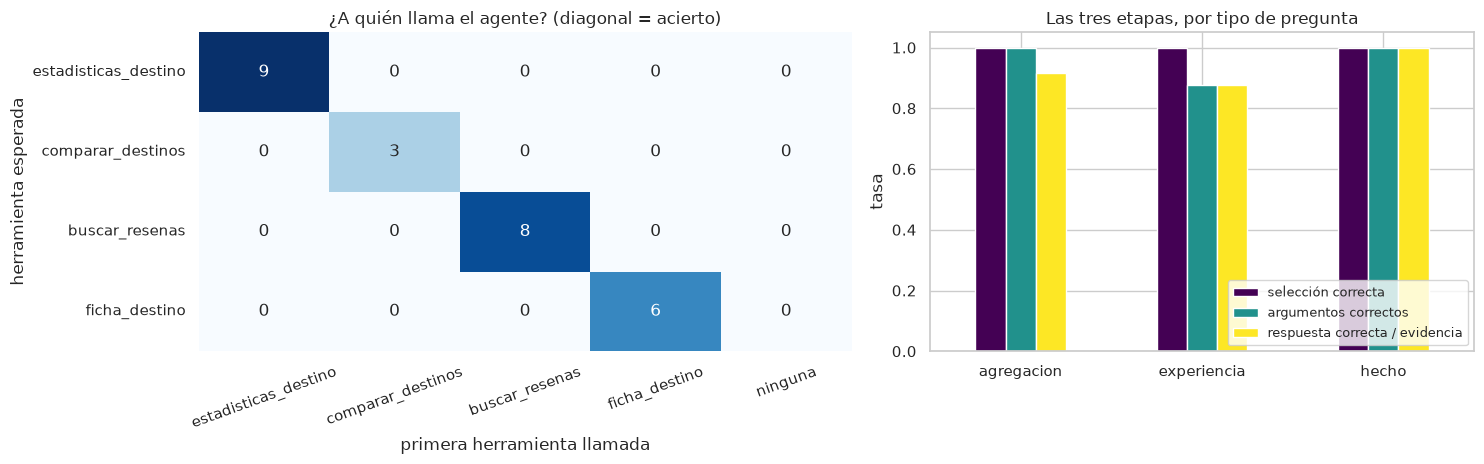

In [14]:
if OLLAMA_OK:
    orden = ["estadisticas_destino", "comparar_destinos", "buscar_resenas", "ficha_destino", "ninguna"]
    matriz = pd.crosstab(ev4["esperada"], ev4["primera"]).reindex(index=orden[:4], columns=orden, fill_value=0)
    fig, ejes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.2, 1]})
    sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ejes[0])
    ejes[0].set(xlabel="primera herramienta llamada", ylabel="herramienta esperada",
                title="¿A quién llama el agente? (diagonal = acierto)")
    ejes[0].tick_params(axis="x", rotation=20)
    por_cat = ev4.groupby("categoria")[["seleccion_ok", "args_ok", "respuesta_ok"]].mean()
    por_cat["respuesta_ok"] = por_cat["respuesta_ok"].where(por_cat.index != E, ev4.loc[ev4["categoria"] == E, "evidencia"].mean())
    por_cat.columns = ["selección correcta", "argumentos correctos", "respuesta correcta / evidencia"]
    por_cat.plot(kind="bar", ax=ejes[1], rot=0, ylim=(0, 1.05), colormap="viridis")
    ejes[1].set(title="Las tres etapas, por tipo de pregunta", xlabel="", ylabel="tasa")
    ejes[1].legend(loc="lower right", fontsize=9)
    plt.tight_layout(); plt.savefig(FIGURAS / "03_seleccion_herramienta.png", dpi=110); plt.show()

**Lectura.** La matriz es diagonal: con las cuatro descripciones completas el agente nunca confunde «cuántos» con «qué dicen». Las barras muestran dónde se pierde lo poco que se pierde: no en la selección, que está en 1 para los tres tipos, sino **un eslabón después**, en los argumentos de una pregunta de experiencia y en la lectura de una cifra. Eso ya contradice la forma fuerte de H2: con buenas descripciones, el cuello de botella no es la elección.

### 7.1 Un fallo, a propósito

Mostrar dónde se equivoca el agente explica más que la tasa de acierto. La celda busca la primera
pregunta donde el agente falló en algún eslabón y muestra su traza completa.

In [15]:
if OLLAMA_OK:
    fallos = ev4[~ev4["seleccion_ok"] | ~ev4["args_ok"] | (ev4["respuesta_ok"] == 0)]
    print(f"Preguntas con algún fallo: {len(fallos)} de {len(ev4)}\n")
    for _, f in fallos.iterrows():
        fila = BANCO.set_index("id").loc[f["id"]]
        print(f"{f['id']} · {fila['pregunta']}\n  esperada: {fila['herramienta']}({fila['args']})"
              f"  valor real: {round(fila['valor'], 2) if isinstance(fila['valor'], float) else fila['valor']}")
        print(f"  traza:    {f['llamadas']}\n  respuesta: {f['respuesta'][:300]}\n")

Preguntas con algún fallo: 2 de 26

A04 · ¿Cuántas reseñas de hoteles hay de Valladolid?
  esperada: estadisticas_destino({'destino': 'Valladolid'})  valor real: 2673
  traza:    [{"herramienta": "estadisticas_destino", "args": {"destino": "Valladolid"}}]
  respuesta: Valladolid tiene un total de 11.637 reseñas de hoteles, con una valoración media de 4.47 de 5 estrellas.

E07 · ¿Qué cuentan los turistas sobre las Barrancas del Cobre en Creel?
  esperada: buscar_resenas({'destino': 'Creel'})  valor real: None
  traza:    [{"herramienta": "buscar_resenas", "args": {"tipo": "", "estrellas_max": null, "k": null, "consulta": "que cuentan los turistas sobre las Barrancas del Cobre en Creel", "destino": "Barrancas del Cobre"}}]
  respuesta: Lo siento, pero no tengo información sobre las Barrancas del Cobre en Creel en el corpus Rest-Mex. Sin embargo, puedo decirte que las Barrancas del Cobre son un lugar turístico famoso en el estado de Chihuahua, México. Según Wikipedia, son un sistema de ca

**Lectura.** Los dos fallos son distintos y ninguno es de selección. En **A04** la herramienta y el argumento son correctos, y la salida contiene la cifra pedida («hoteles: 2673»), pero el modelo **copió el total del destino** (11.637) y lo presentó como reseñas de hoteles: un error de lectura de la salida, que un modelo de 3B comete cuando la respuesta trae varias cifras juntas. En **E07** el agente **inventó un argumento**: pasó «Barrancas del Cobre» como destino en vez de Creel. El servidor respondió honestamente que ese destino no existe, y el modelo, en lugar de reintentar con Creel, rellenó con conocimiento propio atribuido a Wikipedia. Es el mismo patrón que vimos en la primera corrida con `k: null` (D-610): cuando la herramienta devuelve un error, el modelo improvisa en lugar de corregirse.

---

## 8. Más herramientas y peores descripciones (H3)

H3 dice que la elección empeora al ofrecer más herramientas parecidas. Se prueban tres
configuraciones del **mismo** agente sobre las preguntas cuya herramienta esperada es
`estadisticas_destino` o `buscar_resenas`, la pareja que responde «cuántos» y «qué dicen» sobre el
mismo corpus:

1. **2 herramientas**: solo esa pareja. Es la elección más fácil posible.
2. **4 herramientas**: la configuración de §7, con `comparar_destinos` y `ficha_destino` como
   distractores plausibles.
3. **4 herramientas con descripciones de una línea**: los mismos esquemas de argumentos, pero el
   docstring reducido a una frase sin «cuándo usarla» ni «cuándo no». El servidor no cambia: la
   descripción se sustituye en el cliente, que es justo lo que el modelo lee. Esta configuración
   mide cuánto del acierto se debe a las descripciones que escribimos.

,2 herramientas,4 herramientas,4 con descripciones de una línea
selección correcta,0.94,1.00,0.47
argumentos correctos,0.88,0.94,0.06
preguntas con llamadas innecesarias,0.06,0.00,0.53
preguntas sin ninguna llamada,0.00,0.00,0.00
llamadas por pregunta,1.00,1.00,1.00
segundos por pregunta,14.00,13.71,14.18
respuesta correcta (agregación),0.78,0.89,0.00
precisión de la evidencia (experiencia),0.88,0.88,0.68


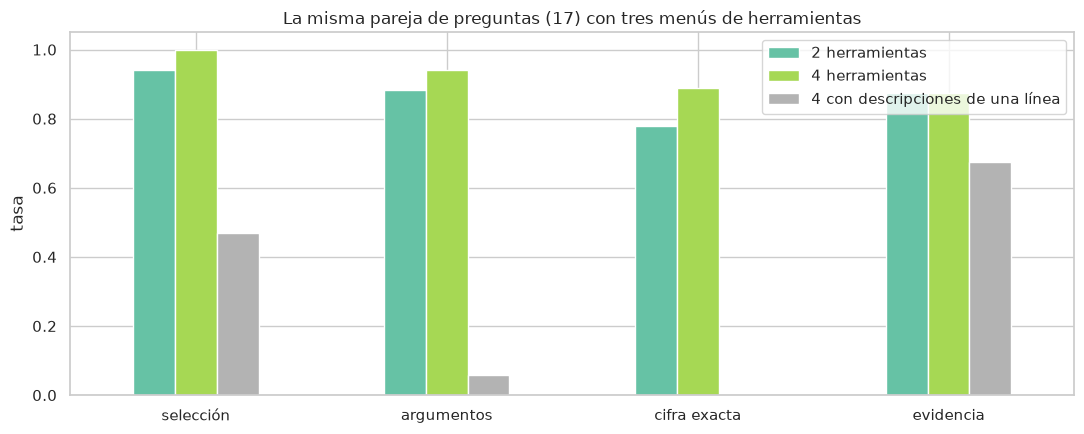

In [16]:
PAREJA = {"estadisticas_destino", "buscar_resenas"}
DESCRIPCION_CORTA = {"estadisticas_destino": "Estadísticas de un destino.",
                     "comparar_destinos": "Compara destinos.",
                     "buscar_resenas": "Busca reseñas.",
                     "ficha_destino": "Ficha de un destino."}
sub_banco = BANCO[BANCO["herramienta"].isin(PAREJA)]

if OLLAMA_OK:
    ev2 = await evaluar(crear_agente([h for h in HERRAMIENTAS if h.name in PAREJA]), sub_banco)
    cortas = [h.model_copy(update={"description": DESCRIPCION_CORTA[h.name]}) for h in HERRAMIENTAS]
    ev4c = await evaluar(crear_agente(cortas), sub_banco)
    ev4_sub = ev4[ev4["id"].isin(sub_banco["id"])]
    configs = {"2 herramientas": ev2, "4 herramientas": ev4_sub, "4 con descripciones de una línea": ev4c}
    for nombre, ev in configs.items():
        ev.assign(config=nombre).to_csv(METRICAS / f"h3_{norm(nombre)}.csv", index=False)
    resumen8 = pd.DataFrame({n: metricas(ev) for n, ev in configs.items()})
    resumen8.loc["respuesta correcta (agregación)"] = [ev.loc[ev["categoria"] == A, "respuesta_ok"].mean() for ev in configs.values()]
    resumen8.loc["precisión de la evidencia (experiencia)"] = [ev.loc[ev["categoria"] == E, "evidencia"].mean() for ev in configs.values()]
    display(resumen8.round(2))

    fig, eje = plt.subplots(figsize=(11, 4.5))
    resumen8.loc[["selección correcta", "argumentos correctos", "respuesta correcta (agregación)",
                  "precisión de la evidencia (experiencia)"]].plot(kind="bar", ax=eje, rot=0, ylim=(0, 1.05),
                                                                  colormap="Set2")
    eje.set(title=f"La misma pareja de preguntas ({len(sub_banco)}) con tres menús de herramientas", ylabel="tasa")
    eje.set_xticklabels(["selección", "argumentos", "cifra exacta", "evidencia"])
    plt.tight_layout(); plt.savefig(FIGURAS / "04_h3_herramientas.png", dpi=110); plt.show()

**Lectura.** El resultado contradice H3 tal como la escribimos. Con **2 herramientas** el agente eligió *peor* que con 4 (94 % frente a 100 %): en A06, «¿cuántas **opiniones** de restaurantes...?», la palabra «opiniones» lo llevó a `buscar_resenas`, y respondió que San Cristóbal tiene «5 reseñas de restaurantes», que es el número de documentos recuperados (son 6.260). Con 4 herramientas esa misma pregunta salió bien. La diferencia es de una sola pregunta sobre 17, así que no afirmamos que más herramientas ayuden, solo que **los dos distractores no estorbaron**. Lo que sí hunde la elección es la **descripción**: con docstrings de una línea, el agente llamó `buscar_resenas` en las **17 de 17 preguntas**, la selección cayó al 47 % (los 8 aciertos son simplemente las preguntas de experiencia), la cifra exacta a 0 % y los argumentos se volvieron absurdos: sin la descripción el modelo no sabe qué significa `tipo` y escribe `tipo: "opiniones de restaurantes"`, `tipo: "negativas"` o `tipo: "destino"`, y en E07 omite el destino por completo. «Busca reseñas» es la frase que más se parece a cualquier pregunta sobre reseñas. El problema práctico de los sistemas con herramientas no es cuántas hay, sino **si su descripción dice cuándo no usarlas**.

---

## 9. Comparación con el RAG del Miniproyecto 5

La última pieza de H1: las mismas 26 preguntas por un **RAG puro**, sin herramientas. Se
reconstruye el RAG de MP5 con sus mismos ingredientes: el codificador E5 con prefijos, las
reseñas del índice de §2.2 y las fichas de Wikipedia partidas en fragmentos de 120 palabras, todo
en un único espacio de búsqueda. El modelo recibe los cinco documentos más parecidos y responde
**solo** con ellos. No hay filtros: el RAG no sabe que «hoteles de Tulum» es un filtro y no un tema.

La tesis no es que uno gane siempre, sino que **cada tipo de pregunta tiene su camino**.

Espacio de búsqueda del RAG: 27,400 reseñas + 1120 fragmentos de fichas.


,modelo solo,RAG puro (MP5),agente con 4 herramientas MCP
agregación (cifra exacta),0.08,0.08,0.92
experiencia (precisión de evidencia),NaN,0.70,0.88
hecho (estado correcto),0.67,1.00,1.00


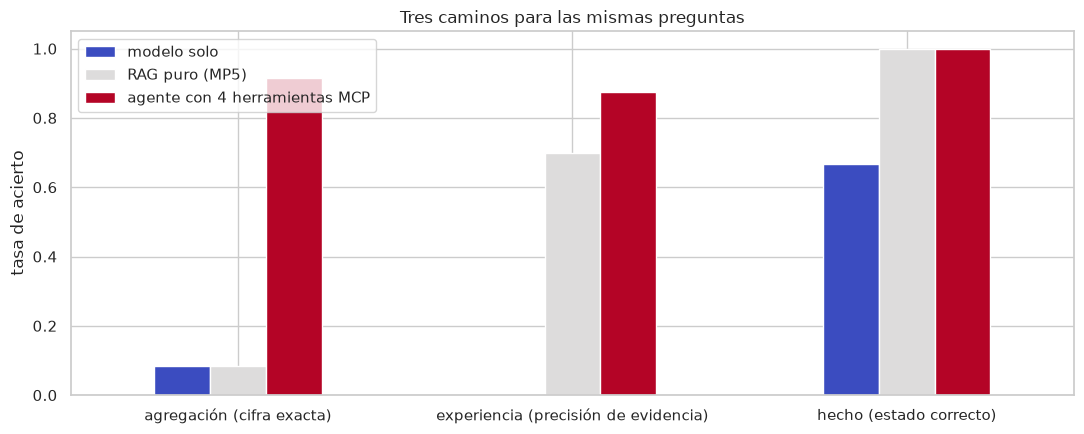

In [17]:
fragmentos = []
for f in fichas:
    palabras = f["texto"].split()
    for i in range(0, len(palabras), 120):
        fragmentos.append({"Town": f["destino"], "Type": "Wikipedia", "Polarity": 0,
                           "texto": " ".join(palabras[i:i + 120])})
fragmentos = pd.DataFrame(fragmentos)
vec_fichas = codificador.encode(("passage: " + fragmentos["texto"]).tolist(), batch_size=64,
                                normalize_embeddings=True).astype(np.float32)
docs_rag = pd.concat([indice.assign(texto=indice["Title"] + ". " + indice["Review"])[["Town", "Type", "Polarity", "texto"]],
                      fragmentos], ignore_index=True)
vec_rag = np.vstack([vectores, vec_fichas])
SISTEMA_RAG = ("Eres un asistente de viajes por México. Responde en español, en pocas frases, usando "
               "SOLO los documentos dados y citando de cuál sacas cada dato.")


async def rag(pregunta, k=5):
    q = codificador.encode(f"query: {pregunta}", normalize_embeddings=True)
    top = docs_rag.iloc[np.argsort(-(vec_rag @ q))[:k]]
    contexto = "\n".join(f"[{i}] {leg(d['Town'])} | {d['Type']} | {int(d['Polarity'])} estrellas: {d['texto'][:400]}"
                         for i, (_, d) in enumerate(top.iterrows(), start=1))
    t0 = time.perf_counter()
    r = (await llm.ainvoke([("system", SISTEMA_RAG), ("user", f"Documentos:\n{contexto}\n\nPregunta: {pregunta}")])).content
    return r, [(leg(d["Town"]), d["Type"], int(d["Polarity"])) for _, d in top.iterrows()], time.perf_counter() - t0


print(f"Espacio de búsqueda del RAG: {len(indice):,} reseñas + {len(fragmentos)} fragmentos de fichas.")
if OLLAMA_OK:
    filas_rag = []
    for _, fila in BANCO.iterrows():
        r, docs, s = await rag(fila["pregunta"])
        filas_rag.append({"id": fila["id"], "categoria": fila["categoria"], "respuesta_rag": r, "s": s,
                          "respuesta_ok": a_float(respuesta_correcta(r, fila)),
                          "evidencia": precision_evidencia(docs, fila["args"]) if fila["categoria"] == E else np.nan})
    ev_rag = pd.DataFrame(filas_rag)
    ev_rag.to_csv(METRICAS / "rag_puro.csv", index=False)

    def puntaje(ev):
        return pd.Series({c: (g["evidencia"] if c == E else g["respuesta_ok"]).astype(float).mean()
                          for c, g in ev.groupby("categoria")})
    comparacion = pd.DataFrame({
        "modelo solo": puntaje(solo).reindex([A, E, H]),
        "RAG puro (MP5)": puntaje(ev_rag),
        "agente con 4 herramientas MCP": puntaje(ev4)})
    comparacion.index = ["agregación (cifra exacta)", "experiencia (precisión de evidencia)", "hecho (estado correcto)"]
    display(comparacion.round(2))
    comparacion.to_csv(METRICAS / "comparacion_caminos.csv")
    fig, eje = plt.subplots(figsize=(11, 4.5))
    comparacion.plot(kind="bar", ax=eje, rot=0, ylim=(0, 1.05), colormap="coolwarm")
    eje.set(title="Tres caminos para las mismas preguntas", ylabel="tasa de acierto")
    plt.tight_layout(); plt.savefig(FIGURAS / "05_rag_vs_agente.png", dpi=110); plt.show()

**Lectura.** Cada camino gana en un tipo de pregunta distinto, que era la tesis. En **agregación** el RAG empata con el modelo solo (1 de 12): ver cinco reseñas no permite contar 45.345. En **hechos** el RAG llega al 100 %, igual que el agente: las fichas de Wikipedia están en su índice y la pregunta «¿en qué estado está?» se parece mucho al primer párrafo de la ficha. Aquí la herramienta no aporta nada sobre la recuperación. En **experiencia** el agente gana (0,88 frente a 0,70), y la diferencia se concentra exactamente donde el EDA lo anticipó: en las dos preguntas sobre **quejas**, E01 y E06, el RAG recupera 0,2 y 0,0 de evidencia pertinente, porque la búsqueda densa trae reseñas del tema correcto pero elogiosas; el agente, con `estrellas_max = 2`, obtiene 1,0 en ambas. La herramienta de recuperación es el mismo RAG con una ventaja decisiva: **filtros de metadatos que el modelo decide aplicar**.

In [18]:
if OLLAMA_OK:
    ejemplo = ev_rag.merge(ev4[["id", "respuesta"]], on="id").merge(BANCO[["id", "pregunta", "valor"]], on="id")
    for _, e in ejemplo[ejemplo["id"].isin(["A03", "E01"])].iterrows():
        print(f"{e['id']} · {e['pregunta']}   (valor real: {e['valor'] if e['valor'] is not None else 'sin cifra'})")
        print(f"  RAG puro: {e['respuesta_rag'][:330]}")
        print(f"  Agente:   {e['respuesta'][:330]}\n")

A03 · ¿Cuántas reseñas de 1 estrella tiene Tulum?   (valor real: 798)
  RAG puro: Lo siento, pero no tengo información sobre reseñas de 1 estrella de Tulum. Sin embargo, puedo decirte que no hay reseñas de 1 estrella en los documentos proporcionados. Todos los comentarios son de 5 estrellas.
  Agente:   Tulum tiene 798 reseñas con 1 estrella.

E01 · ¿De qué se quejan los turistas en los hoteles de Tulum?   (valor real: sin cifra)
  RAG puro: Según los documentos proporcionados, los turistas en los hoteles de Tulum se quejan de lo siguiente:

* Falta de playa en algunos hoteles (Tulum | Hotel | 3 estrellas y Tulum | Hotel | 2 estrellas)
* Comida horrible o normal (Tulum | Hotel | 3 estrellas y Tulum | Hotel | 2 estrellas)
* Vino avinagrado (Tulum | Hotel | 2 estrella
  Agente:   Los turistas que se quejan de la limpieza en los hoteles de Tulum mencionan que la habitación estaba sucia, había cucarachas, y que el personal de recepción no era muy servicial. También mencionan que el hotel n

**Lectura.** Los dos ejemplos resumen la sección. Ante A03 el RAG no solo falla: **afirma que «todos los comentarios son de 5 estrellas»**, generalizando desde los cinco documentos que recuperó, que es exactamente el sesgo de muestra que motivó el proyecto. Ante E01 el RAG mezcla reseñas de 3 estrellas (quejas tibias) con las negativas, mientras el agente cita solo reseñas de 1 y 2 estrellas de hoteles de Tulum.

---

## 10. El chatbot

La interfaz de Gradio envuelve al mismo agente de §7 y, debajo de cada respuesta, muestra **la
traza**: qué herramienta MCP llamó, con qué argumentos, y las **fuentes** que devolvió (la cifra
calculada, las reseñas con su destino, tipo y estrellas, o el artículo de Wikipedia con su URL).
Así cada afirmación del bot se puede rastrear hasta el documento que la sostiene.

**Guion para el video (máximo 2 minutos).** Ejecutar la celda de la interfaz y hacer dos preguntas:

1. *«¿Cuántas reseñas de 1 estrella tiene Tulum?»*: llama `estadisticas_destino` y responde con la
   cifra exacta del corpus completo.
2. *«¿De qué se quejan los turistas en los hoteles de Tulum?»*: llama `buscar_resenas` con
   filtros y cita las reseñas con su destino, tipo y estrellas.
3. Si sobra tiempo: *«¿En qué estado de México está Real de Catorce?»*, que cita la ficha de
   Wikipedia con su URL.

Primero, la función que da formato a la respuesta, probada fuera de la interfaz para que el
resultado quede en el notebook ejecutado.

In [19]:
PATRON_FUENTE = re.compile(r"^(\[\d+\] .+|Ficha de .+|Destino: .+|Total de reseñas: .+|Valoración media: .+|"
                           r"Reseñas por .+|\d+\. .+: media .+)$", flags=re.M)


def formatear(r):
    partes = [r["respuesta"]]
    if r["llamadas"]:
        partes.append("\n---\n**Herramientas MCP usadas**")
        partes += [f"- `{c['herramienta']}({', '.join(f'{k}={v!r}' for k, v in c['args'].items())})`"
                   for c in r["llamadas"]]
        fuentes = [m.group(0) for s in r["salidas"] for m in PATRON_FUENTE.finditer(s)]
        if fuentes:
            partes.append("\n**Fuentes**")
            partes += [f"- {f[:220]}{'…' if len(f) > 220 else ''}" for f in fuentes[:8]]
    else:
        partes.append("\n---\n*No se llamó ninguna herramienta: la respuesta no está respaldada por el corpus.*")
    return "\n".join(partes)


async def responder(mensaje, historial):
    return formatear(await preguntar(AGENTE, mensaje))


if OLLAMA_OK:
    print(await responder("¿De qué se quejan los turistas en los hoteles de Tulum?", []))

Los turistas que se quejan de la limpieza en los hoteles de Tulum mencionan que la habitación estaba sucia, había cucarachas, y que el personal de recepción no era muy servicial. También mencionan que el hotel no cumplía con sus expectativas, especialmente en cuanto a la calidad de los servicios y la limpieza. Algunos turistas también mencionan que el personal del restaurante era amable, pero que el resto del hotel no era muy agradable.

---
**Herramientas MCP usadas**
- `buscar_resenas(consulta='quejas sobre la limpieza en hoteles', destino='Tulum', tipo='Hotel', estrellas_max='2', k='10')`

**Fuentes**
- [1] Tulum | Hotel | 1 estrellas | "Una tristeza, estafa y perdida de tiempo": No quise perder tiempo en venir a escribir mi horrible experiencia, todo el mundo sabe o más bien es un secreto a voces que los hoteleros de l…
- [2] Tulum | Hotel | 2 estrellas | "Es la primera vez que viajaba después de haber adquirido la membresía. Hubo varias cosas que no me gustaron": La comunicación d

La celda que levanta la interfaz. Corre dentro del notebook y también en `http://localhost:7860`.

In [20]:
import gradio as gr

if OLLAMA_OK:
    demo = gr.ChatInterface(
        responder,
        title="Agente de viajes MCP · Rest-Mex 2025",
        description=("Pregunta por destinos turísticos de México. El agente elige entre 4 herramientas MCP "
                     "(estadísticas, ranking, búsqueda de reseñas y fichas de Wikipedia) y cita lo que usó."),
        examples=["¿Cuántas reseñas de 1 estrella tiene Tulum?",
                  "¿De qué se quejan los turistas en los hoteles de Tulum?",
                  "¿En qué estado de México está Real de Catorce?",
                  "¿Qué destino tiene los restaurantes mejor valorados?"],
        run_examples_on_click=False)
    demo.launch(server_port=7860, inline=True, prevent_thread_lock=True, quiet=True)
else:
    print("Ollama no disponible: la interfaz no se levanta.")

---

## 11. Conclusiones y limitaciones


**¿Cuándo conviene una herramienta y cuándo basta con recuperar texto?** Conviene una herramienta de cálculo siempre que la pregunta sea una **agregación** (conteo, media, ranking): ningún sistema que vea una muestra puede responderla, y el agente pasó de 1 de 12 a 11 de 12. Basta con recuperar texto para **hechos** que están escritos en un documento (el RAG puro acertó 6 de 6). Y para **experiencias** gana la recuperación expuesta como herramienta, porque el modelo puede añadir filtros de destino, tipo y polaridad que la búsqueda densa no infiere sola (0,88 frente a 0,70 de evidencia pertinente).

**¿Sabe el agente elegir?** Sí, **si las descripciones se lo dicen**. Con los docstrings que escribimos, `llama3.2:3b` eligió bien 26 de 26 veces; con descripciones de una línea, 8 de 17.

| Hipótesis | Veredicto | Cifra que lo sostiene |
|---|---|---|
| **H1** · la agregación necesita herramienta | **Confirmada** | cifra exacta: agente 11/12, modelo solo 1/12, RAG puro 1/12 |
| **H2** · el cuello de botella es la elección, no la herramienta | **Parcial** | la herramienta nunca falló, pero la elección tampoco (26/26); los errores fueron un argumento inventado, una lectura equivocada y un esquema intolerante a `null` |
| **H3** · más herramientas, peor elección | **Refutada tal como se planteó** | 2 herramientas: 94 %, 4: 100 %; con descripciones de una línea: 47 % |

**Qué recomendaríamos.** Cuatro herramientas con docstrings que digan **cuándo usarlas y cuándo no**, esquemas tolerantes con lo que un modelo pequeño escribe de verdad (`null`, números como texto, nombres con tildes), salidas con una cifra por línea para que el modelo no copie la equivocada, y mensajes de error que sugieran la corrección («¿quisiste decir...?»). El protocolo hizo su parte: cada ida y vuelta por MCP costó menos de 60 ms, frente a 7 a 22 s de modelo.

**Limitaciones, incluidas las que nos dejan en mal lugar.**

- **El banco es pequeño y propio**: 26 preguntas, con diferencias de una pregunta entre configuraciones. Las tasas son indicativas, no estimaciones con intervalo.
- **Escribimos los docstrings y el banco las mismas personas.** Los ejemplos de los docstrings («¿cuántas reseñas tiene...?») se parecen a las preguntas, así que el 100 % de selección es probablemente optimista frente a usuarios reales. La ablación de §8 muestra cuánto depende de eso.
- **Un solo modelo, de 3B, con temperatura 0 y semilla fija**, y aun así Ollama en CPU no es determinista bit a bit: entre dos corridas completas, las métricas del agente coincidieron (salvo lo que corrigió D-610), pero alguna redacción del modelo solo cambió (en A01 pasó de inventar «aproximadamente 12.000» a admitir que no sabía). Tampoco sabemos cómo cambian las conclusiones con otro modelo o con temperatura mayor.
- **La métrica de experiencia mide la evidencia, no la redacción.** Que los documentos sean pertinentes no garantiza un buen resumen; en E01 el agente estrechó la consulta a la limpieza por iniciativa propia.
- **El RAG de §9 es una reconstrucción** con los mismos ingredientes de MP5 (E5, reseñas y fichas), no su código exacto, y busca sobre la muestra de §2.2.
- **Latencias de CPU** (D-607): con GPU las respuestas serían varias veces más rápidas, sin cambiar la elección de herramientas.

### Apagado

La última celda cierra la interfaz y apaga los servidores MCP. Se llama dos veces a propósito: la
segunda no encuentra nada que apagar y no falla, que es lo que garantiza que una ejecución
interrumpida no deje el puerto ocupado para la siguiente.

In [21]:
if OLLAMA_OK and "demo" in globals():
    demo.close()
print("Primer apagado: ", apagar_servidores())
print("Segundo apagado:", apagar_servidores())
print(f"Tiempo total de la ejecución: {(time.perf_counter() - T_INICIO) / 60:.1f} min")

Closing server running on port: 7860


Primer apagado:  {'corpus': 'libre', 'busqueda': 'libre'}
Segundo apagado: {'corpus': 'libre', 'busqueda': 'libre'}
Tiempo total de la ejecución: 31.8 min
